# Miniproyecto 3. Clasificación Multi-Etiqueta de Artículos de Noticias de la BBC usando Transformers

Los artículos de noticias contienen una gran cantidad de información categórica y temática, con temas que abarcan desde política y tecnología hasta deportes y cultura. Muchos artículos pueden abarcar varios temas a la vez. Este proyecto tiene como objetivo desarrollar un sistema de clasificación multi-clase que pueda asignar una categoría a cada artículo de noticias de la BBC, utilizando la potencia de los modelos transformer para capturar el contexto y asignar etiquetas múltiples de manera precisa

## Introducción a los Transformers
Los modelos basados en transformers, como BERT, son especialmente adecuados para analizar texto debido a su capacidad para entender relaciones contextuales complejas entre palabras y frases. Esto permite a los transformers abordar de manera efectiva la clasificación multi-clase, capturando de manera simultánea la pertenencia de un artículo a múltiples temas sin necesidad de procesar secuencialmente, como ocurre en los modelos recurrentes.

## Objetivo
• Desarrollar un modelo de clasificación multi-clase basado en transformers que identifique la categoría de artículos de noticias de la BBC.

## Conjunto de Datos
• Utilizaremos un dataset de artículos de la BBC etiquetados con múltiples categorías temáticas, como "Sport", "Bussiness", "Politics", "Tech", entre otros.
• Los datos los pueden obtener usando la siguiente línea de código en Python: kagglehub.dataset_download("jacopoferretti/bbc-articles-dataset")

## Actividades por Realizar
**1.Preprocesamiento del Texto:** Crear un pipeline para procesar los artículos, incluyendo la limpieza del texto, tokenización y la preparación de secuencias utilizando embeddings derivados de un modelo preentrenado como BERT. En este paso se debe garantizar que el texto y las etiquetas estén en el formato adecuado para ser interpretado por el modelo de clasificación multi-clase.

**2.Implementación de la Arquitectura de Transformers:** Usar un modelo de transformers preentrenado, como BERT o RoBERTa, y adaptarlo a la clasificación multi-clase. Esto implicará añadir una capa de salida que permita al modelo generar una predicción de la categoría. Para ello, puede utilizar el método BertForSequenceClassification, disponible en la librería “transformers” vista en el laboratorio de la semana. Recuerde justificar la elección del modelo y de las capas adicionales, explicando cómo cada ajuste facilita la tarea de clasificación multi-clase.

**3.Entrenamiento y Evaluación del Modelo:** Dividir el dataset en conjuntos de entrenamiento, validación y prueba. Entrenar el modelo en el conjunto de entrenamiento y evaluar su rendimiento con el conjunto de prueba. Reportar métricas como precisión, recall, F1-score, y también un análisis de precisión para cada categoría, resaltando las categorías en las que el modelo presenta un mejor o peor rendimiento. Puede utilizar una GPU para entrenar el modelo durante 2 a 5 épocas, recuerde que el problema es un problema de clasificación multi-clase, donde la función de activación debería ser softmax.

## Importación de librerías

In [2]:
import os
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'  # cuBLAS determinista
import re
import copy
import time
import random
import string
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import contractions as ct
import torch
import torch.nn as nn
from torch.optim import AdamW
from torch.utils.data import TensorDataset, DataLoader
from torchview import draw_graph
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report, f1_score, confusion_matrix
from transformers import (DistilBertForSequenceClassification, DistilBertTokenizer,
                          RobertaForSequenceClassification, RobertaTokenizer,
                          get_linear_schedule_with_warmup)
from transformers import logging as hf_logging

warnings.filterwarnings('ignore')
pd.set_option('display.max_colwidth', 80)

# Carpeta donde se guardan las figuras exportadas
FIG_DIR = 'figuras'
os.makedirs(FIG_DIR, exist_ok=True)

w:\MiniConda\envs\deep-nlp\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Inicialización de semillas

In [3]:
SEED = 42

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

# Algoritmos deterministas para que cada ejecución entregue los mismos resultados
torch.use_deterministic_algorithms(True)
seed_everything(SEED)

### Dispositivo de cómputo

In [4]:
if torch.cuda.is_available():
    print("Nombre de la GPU:", torch.cuda.get_device_name(0))

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Usando dispositivo: {device}')

Nombre de la GPU: NVIDIA GeForce RTX 5070 Ti
Usando dispositivo: cuda


### Carga de datos

In [5]:
path =  kagglehub.dataset_download("jacopoferretti/bbc-articles-dataset")
print("Path to dataset files:", path)
print(os.listdir(path))

Path to dataset files: C:\Users\Cador-PC\.cache\kagglehub\datasets\jacopoferretti\bbc-articles-dataset\versions\16
['archive', 'archive (2)', 'bbc_news_text_complexity_summarization.csv']


In [6]:
df = pd.read_csv(os.path.join(path, 'bbc_news_text_complexity_summarization.csv'))
print(df.head())

                                                                              text  \
0  Ad sales boost Time Warner profit\n\nQuarterly profits at US media giant Tim...   
1  Dollar gains on Greenspan speech\n\nThe dollar has hit its highest level aga...   
2  Yukos unit buyer faces loan claim\n\nThe owners of embattled Russian oil gia...   
3  High fuel prices hit BA's profits\n\nBritish Airways has blamed high fuel pr...   
4  Pernod takeover talk lifts Domecq\n\nShares in UK drinks and food firm Allie...   

     labels  no_sentences  Flesch Reading Ease Score  \
0  business            26                      62.17   
1  business            17                      65.56   
2  business            14                      69.21   
3  business            24                      62.98   
4  business            17                      70.63   

   Dale-Chall Readability Score  \
0                          9.72   
1                          9.09   
2                          9.66   
3     

### Revisión de características del dataset

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2127 entries, 0 to 2126
Data columns (total 7 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   text                          2127 non-null   str    
 1   labels                        2127 non-null   str    
 2   no_sentences                  2127 non-null   int64  
 3   Flesch Reading Ease Score     2127 non-null   float64
 4   Dale-Chall Readability Score  2127 non-null   float64
 5   text_rank_summary             2127 non-null   str    
 6   lsa_summary                   2127 non-null   str    
dtypes: float64(2), int64(1), str(4)
memory usage: 116.4 KB


El dataset tiene 2127 artículos y 7 columnas.

- `text` contiene el artículo completo, con título y cuerpo.
- `labels` es la categoría de la noticia y será la variable objetivo.
- `no_sentences` es el número de oraciones del artículo.
- `Flesch Reading Ease Score` y `Dale-Chall Readability Score` miden la legibilidad del texto.
- `text_rank_summary` y `lsa_summary` son resúmenes automáticos generados con TextRank y con análisis semántico latente.

#### Muestra de un artículo y su etiqueta

In [8]:
print(df['text'].iloc[0])
print("Categoría:", df['labels'].iloc[0])

Ad sales boost Time Warner profit

Quarterly profits at US media giant TimeWarner jumped 76% to $1.13bn (£600m) for the three months to December, from $639m year-earlier.

The firm, which is now one of the biggest investors in Google, benefited from sales of high-speed internet connections and higher advert sales. TimeWarner said fourth quarter sales rose 2% to $11.1bn from $10.9bn. Its profits were buoyed by one-off gains which offset a profit dip at Warner Bros, and less users for AOL.

Time Warner said on Friday that it now owns 8% of search-engine Google. But its own internet business, AOL, had has mixed fortunes. It lost 464,000 subscribers in the fourth quarter profits were lower than in the preceding three quarters. However, the company said AOL's underlying profit before exceptional items rose 8% on the back of stronger internet advertising revenues. It hopes to increase subscribers by offering the online service free to TimeWarner internet customers and will try to sign up AOL

### Selección de columnas

Para la clasificación solo se necesitan las columnas `text` y `labels`, así que se descartan las demás.

In [9]:
df_clasificacion = df[['text', 'labels']]

print("Dimensiones del nuevo dataset:", df_clasificacion.shape)
print(df_clasificacion.head())

Dimensiones del nuevo dataset: (2127, 2)
                                                                              text  \
0  Ad sales boost Time Warner profit\n\nQuarterly profits at US media giant Tim...   
1  Dollar gains on Greenspan speech\n\nThe dollar has hit its highest level aga...   
2  Yukos unit buyer faces loan claim\n\nThe owners of embattled Russian oil gia...   
3  High fuel prices hit BA's profits\n\nBritish Airways has blamed high fuel pr...   
4  Pernod takeover talk lifts Domecq\n\nShares in UK drinks and food firm Allie...   

     labels  
0  business  
1  business  
2  business  
3  business  
4  business  


### Verificación de clases del dataset

In [10]:
df_clasificacion["labels"].value_counts()

labels
sport            505
business         503
politics         403
entertainment    369
tech             347
Name: count, dtype: int64

Porcentaje de artículos por categoría.

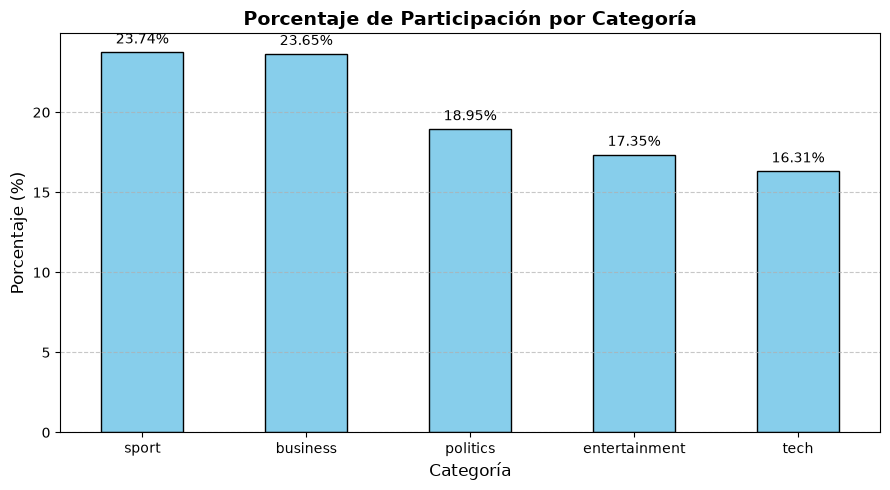

In [11]:
porcentajes = df_clasificacion['labels'].value_counts(normalize=True) * 100

plt.figure(figsize=(9, 5))
ax = porcentajes.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Porcentaje de Participación por Categoría', fontsize=14, fontweight='bold')
plt.xlabel('Categoría', fontsize=12)
plt.ylabel('Porcentaje (%)', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)

for p in ax.patches:
    height = p.get_height()
    ax.annotate(f"{height:.2f}%", (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom', xytext=(0, 4), textcoords='offset points', fontsize=10)

plt.tight_layout()
plt.show()

Hay 5 categorías. Sport y business son las más frecuentes, con 23.74 % y 23.65 % de los artículos, y entertainment y tech las menos frecuentes, con 17.35 % y 16.31 %. Con 505 artículos en sport y 347 en tech, las clases están razonablemente balanceadas.

### Verificación y tratamiento de datos nulos y duplicados

In [12]:
# Datos nulos
print(f'Data:\n{df_clasificacion.isna().sum()}')

Data:
text      0
labels    0
dtype: int64


In [13]:
# Duplicados
df_clasificacion.duplicated().sum()

np.int64(0)

No hay datos nulos ni duplicados.

## División de los datos

In [14]:
X= df_clasificacion.drop(columns='labels')
y= df_clasificacion['labels']

### Separación en entrenamiento, validación y prueba

In [15]:
# 70 % entrenamiento, 15 % validación y 15 % prueba, estratificado por categoría
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=42, stratify=y)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.1765, random_state=42, stratify=y_train)  # 0.1765 x 0.85 = 0.15

print(X.shape[0], X_train.shape[0], X_test.shape[0], X_val.shape[0])

2127 1488 320 319


La división quedó en 1488 artículos de entrenamiento, 319 de validación y 320 de prueba.

### Codificación de las etiquetas

In [16]:
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)  # Se ajusta solo con entrenamiento
y_val_encoded = le.transform(y_val)
y_test_encoded = le.transform(y_test)
print(le.classes_)

['business' 'entertainment' 'politics' 'sport' 'tech']


In [17]:
#Visualización de etiquetas de entrenamiento
pd.Series(y_train_encoded).value_counts()

3    353
0    352
2    282
1    258
4    243
Name: count, dtype: int64

## Pipeline de limpieza y preprocesamiento

La misma función se usa para los dos modelos. El texto se pasa a minúsculas solo para DistilBERT, cuyo vocabulario no distingue mayúsculas. RoBERTa sí las distingue y los nombres propios son una pista útil para la categoría.

In [18]:
def limpiar_texto(text, minusculas=True):
    """Limpieza básica del texto antes de tokenizar."""
    text = str(text)
    if minusculas:
        text = text.lower()
    text = re.sub(r'<br\s*/?>', ' ', text)                          # etiquetas HTML
    text = re.sub(r'https?://\S+|www\.\S+', '', text)               # URLs
    text = ct.fix(text)                                             # contracciones
    text = re.sub(f'[{re.escape(string.punctuation)}]', ' ', text)  # puntuación
    text = re.sub(r'\s+', ' ', text).strip()                        # espacios repetidos
    return text


def preprocess_dataset(texts, tokenizer, max_len=512, minusculas=True):
    """Limpia, tokeniza, trunca a max_len y rellena con el token de padding del modelo.
    El tokenizador conserva el token de cierre de secuencia al truncar."""
    cleaned = [limpiar_texto(t, minusculas) for t in texts]
    enc = tokenizer(cleaned, truncation=True, padding='max_length', max_length=max_len, return_tensors='pt')
    return enc['input_ids'], enc['attention_mask']


def porcentaje_truncados(texts, tokenizer, max_len=512, minusculas=True):
    """Porcentaje de textos cuya tokenización supera max_len."""
    longitudes = [len(tokenizer(limpiar_texto(t, minusculas))['input_ids']) for t in texts]
    return 100 * np.mean(np.array(longitudes) > max_len)

## Implementación de arquitectura de transformers

### Instanciación del modelo DistilBERT preentrenado

Se usa `DistilBertForSequenceClassification` con `num_labels=5` y la implementación estándar de la atención. Junto con los algoritmos deterministas de PyTorch, esto hace que cada ejecución del notebook entregue los mismos resultados.

In [19]:
tokenizer = DistilBertTokenizer.from_pretrained('distilbert-base-uncased')

seed_everything(SEED)
model = DistilBertForSequenceClassification.from_pretrained(
    'distilbert-base-uncased', num_labels=5, attn_implementation='eager').to(device)

print(model)

Loading weights: 100%|██████████| 100/100 [00:00<00:00, 2295.19it/s]
[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


DistilBertForSequenceClassification(
  (distilbert): DistilBertModel(
    (embeddings): Embeddings(
      (word_embeddings): Embedding(30522, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (transformer): Transformer(
      (layer): ModuleList(
        (0-5): 6 x TransformerBlock(
          (attention): DistilBertSelfAttention(
            (q_lin): Linear(in_features=768, out_features=768, bias=True)
            (k_lin): Linear(in_features=768, out_features=768, bias=True)
            (v_lin): Linear(in_features=768, out_features=768, bias=True)
            (out_lin): Linear(in_features=768, out_features=768, bias=True)
            (dropout): Dropout(p=0.1, inplace=False)
          )
          (sa_layer_norm): LayerNorm((768,), eps=1e-12, elementwise_affine=True, bias=True)
          (ffn): FFN(
            (dropout): Dropout(

### Visualización del modelo

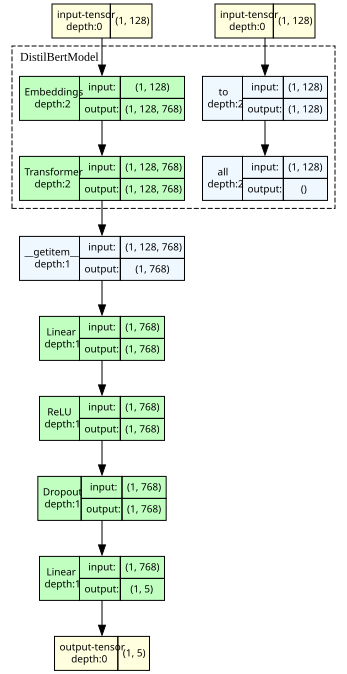

In [20]:
model.eval()

# Entrada de prueba de 128 tokens solo para construir el grafo
dummy_input_ids = torch.randint(0, model.config.vocab_size, (1, 128), dtype=torch.long).to(device)
dummy_attention_mask = torch.ones((1, 128), dtype=torch.long).to(device)

model_graph = draw_graph(
    model,
    input_data=(dummy_input_ids, dummy_attention_mask),
    expand_nested=True,
    graph_name='DistilBert_BBC',
    depth=2
)

model_graph.visual_graph.render(filename=os.path.join(FIG_DIR, 'distilbert_architecture'), format='svg', cleanup=True)
model_graph.visual_graph

### Resumen del flujo dimensional del modelo

B es el tamaño del lote. El grafo usa una entrada de prueba de 128 tokens, pero en el entrenamiento la longitud es 512.

| Componente | Salida | Función |
| :--- | :--- | :--- |
| Entrada | B × 512 | input_ids y máscara de atención |
| DistilBERT, 6 bloques | B × 512 × 768 | Representación contextual de cada token |
| Token [CLS] | B × 768 | Resumen del artículo |
| pre_classifier, ReLU y Dropout | B × 768 | Transformación no lineal y regularización |
| classifier | B × 5 | Logits de las 5 categorías |
| Softmax | B × 5 | Probabilidad de cada categoría |

`DistilBertForSequenceClassification` añade sobre el codificador la capa `pre_classifier` de 768 a 768 con ReLU, un Dropout de 0.2 y la capa `classifier` de 768 a 5. Estas capas se inicializan aleatoriamente, por eso el reporte de carga las marca como MISSING.

### Preprocesamiento de cada conjunto

Cada conjunto se procesa por separado con una longitud máxima de 512 tokens, el límite de DistilBERT. Los artículos más largos se truncan.

In [ ]:
X_train_ids, train_masks = preprocess_dataset(X_train['text'], tokenizer, minusculas=False)
X_val_ids, val_masks = preprocess_dataset(X_val['text'], tokenizer,  minusculas=False)
X_test_ids, test_masks = preprocess_dataset(X_test['text'], tokenizer,  minusculas=False)

print("Train:", tuple(X_train_ids.shape), "Val:", tuple(X_val_ids.shape), "Test:", tuple(X_test_ids.shape))
print(f"Artículos de entrenamiento con más de 512 tokens: {porcentaje_truncados(X_train['text'], tokenizer):.1f} %")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (523 > 512). Running this sequence through the model will result in indexing errors


Train: (1488, 512) Val: (319, 512) Test: (320, 512)
Artículos de entrenamiento con más de 512 tokens: 25.7 %


### Definición de optimizador y función de pérdida

### Optimizador

Se usa AdamW, la variante de Adam con decaimiento de pesos desacoplado propuesta por [Loshchilov y Hutter, 2019](https://arxiv.org/abs/1711.05101), que es el optimizador habitual para ajustar Transformers. La tasa de aprendizaje de 2e-5, el lote de 16 y las 4 épocas están dentro de los rangos que recomiendan [Devlin et al., 2019](https://arxiv.org/abs/1810.04805) para el fine-tuning de BERT. La tasa sube linealmente durante el primer 10 % de los pasos y luego decae hasta cero, igual que en el entrenamiento de BERT.

### Función de pérdida

`nn.CrossEntropyLoss` aplica log-softmax sobre los logits y calcula la entropía cruzada con las etiquetas como enteros. Por eso el modelo entrega logits durante el entrenamiento y la softmax se aplica en la inferencia para obtener probabilidades.

In [22]:
LEARNING_RATE = 2e-5
WEIGHT_DECAY = 0.01
BATCH_SIZE = 16
N_EPOCHS = 4
WARMUP = 0.1

criterion = nn.CrossEntropyLoss()

### Funciones de entrenamiento y evaluación

Las mismas funciones se usan para DistilBERT y RoBERTa. En cada época se calcula la pérdida de validación y al final se restauran los pesos de la época con menor pérdida.

In [23]:
def crear_loader(input_ids, masks, labels, shuffle=False):
    dataset = TensorDataset(input_ids, masks, torch.tensor(labels, dtype=torch.long))
    return DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=shuffle)


def entrenar_modelo(model, train_loader, val_loader, n_epochs=N_EPOCHS, verbose=True):
    """Fine-tuning con AdamW y warmup lineal. Conserva los pesos con menor pérdida de validación."""
    optimizer = AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    pasos = n_epochs * len(train_loader)
    scheduler = get_linear_schedule_with_warmup(optimizer, int(WARMUP * pasos), pasos)

    history = {'loss': [], 'val_loss': []}
    best_val_loss, best_state = float('inf'), None
    start = time.time()

    for epoch in range(n_epochs):
        model.train()
        running_loss = 0.0
        for xb, mask_b, yb in train_loader:
            xb, mask_b, yb = xb.to(device), mask_b.to(device), yb.to(device)
            optimizer.zero_grad()
            logits = model(input_ids=xb, attention_mask=mask_b).logits
            loss = criterion(logits, yb)
            loss.backward()
            optimizer.step()
            scheduler.step()
            running_loss += loss.item() * xb.size(0)
        train_loss = running_loss / len(train_loader.dataset)

        model.eval()
        val_running_loss = 0.0
        with torch.no_grad():
            for xb, mask_b, yb in val_loader:
                xb, mask_b, yb = xb.to(device), mask_b.to(device), yb.to(device)
                logits = model(input_ids=xb, attention_mask=mask_b).logits
                val_running_loss += criterion(logits, yb).item() * xb.size(0)
        val_loss = val_running_loss / len(val_loader.dataset)

        history['loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        mejora = val_loss < best_val_loss
        if mejora:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
        if verbose:
            marca = " - mejor modelo" if mejora else ""
            print(f"Época {epoch+1}/{n_epochs} - loss: {train_loss:.4f} - val_loss: {val_loss:.4f}{marca}")

    model.load_state_dict(best_state)
    history['tiempo'] = time.time() - start
    if verbose:
        print(f"Entrenamiento finalizado en {history['tiempo']:.1f} s")
    return history


def predecir(model, loader):
    """Devuelve etiquetas reales, predicciones y probabilidades softmax."""
    model.eval()
    probs, targets = [], []
    with torch.no_grad():
        for xb, mask_b, yb in loader:
            logits = model(input_ids=xb.to(device), attention_mask=mask_b.to(device)).logits
            probs.append(torch.softmax(logits, dim=-1).cpu())
            targets.append(yb)
    probs = torch.cat(probs).numpy()
    targets = torch.cat(targets).numpy()
    return targets, probs.argmax(axis=1), probs


def visualization_history(history, titulo):
    """Curvas de pérdida de entrenamiento y validación por época."""
    epocas = range(1, len(history['loss']) + 1)
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(epocas, history['loss'], color='#5a2ff4', marker='.', lw=2, label='Pérdida entrenamiento')
    ax.plot(epocas, history['val_loss'], color='#60d13e', marker='.', lw=2, label='Pérdida validación')
    ax.set_xticks(list(epocas))
    ax.set_xlabel('Época', fontsize=12)
    ax.set_ylabel('Pérdida', fontsize=12)
    ax.set_title(titulo, fontsize=13)
    ax.grid()
    ax.legend(fontsize=12, loc='upper right')
    plt.tight_layout()
    plt.show()


def graficar_confusion(cm, titulo, cmap='Blues'):
    plt.figure(figsize=(8, 6))
    sns.heatmap(cm, annot=True, fmt='d', cmap=cmap, xticklabels=le.classes_, yticklabels=le.classes_)
    plt.xlabel('Clase Predicha')
    plt.ylabel('Clase Real')
    plt.title(titulo)
    plt.show()


def tabla_predicciones(indices, y_true, y_pred, probs, textos):
    """Título del artículo, clase real, clase predicha y probabilidad asignada a la predicción."""
    return pd.DataFrame({
        'Título': [textos.iloc[i].split('\n')[0] for i in indices],
        'Real': le.classes_[y_true[indices]],
        'Predicha': le.classes_[y_pred[indices]],
        'Probabilidad': probs[indices, y_pred[indices]].round(3),
    }, index=indices)

### Entrenamiento del modelo

In [24]:
train_loader = crear_loader(X_train_ids, train_masks, y_train_encoded, shuffle=True)
val_loader = crear_loader(X_val_ids, val_masks, y_val_encoded)
test_loader = crear_loader(X_test_ids, test_masks, y_test_encoded)

seed_everything(SEED)
history = entrenar_modelo(model, train_loader, val_loader)

Época 1/4 - loss: 0.9325 - val_loss: 0.1542 - mejor modelo
Época 2/4 - loss: 0.1209 - val_loss: 0.0704 - mejor modelo
Época 3/4 - loss: 0.0508 - val_loss: 0.0600 - mejor modelo
Época 4/4 - loss: 0.0319 - val_loss: 0.0571 - mejor modelo
Entrenamiento finalizado en 61.7 s


### Pérdida a lo largo del entrenamiento

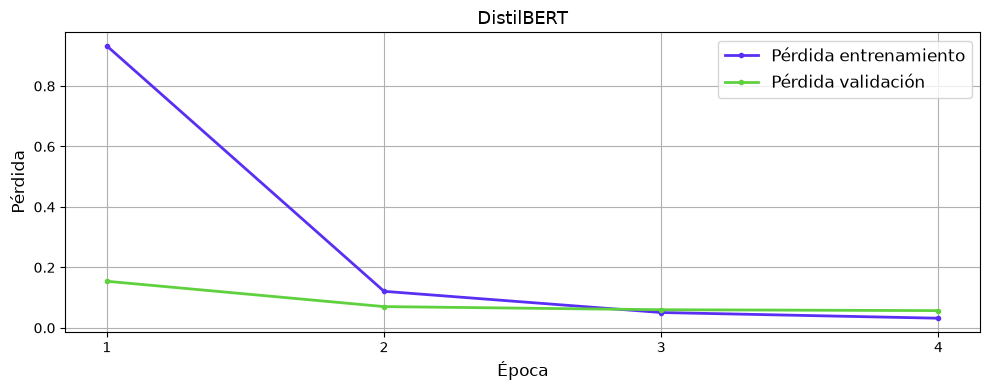

In [25]:
visualization_history(history, 'DistilBERT')

La pérdida de validación baja en las cuatro épocas y termina en 0.0571, así que se conservan los pesos de la última época. No hay señales de sobreajuste.

### Evaluación del modelo con conjunto de prueba

Reporte de clasificación DistilBERT

               precision    recall  f1-score   support

     business     0.9610    0.9737    0.9673        76
entertainment     1.0000    0.9818    0.9908        55
     politics     1.0000    0.9508    0.9748        61
        sport     1.0000    1.0000    1.0000        76
         tech     0.9455    1.0000    0.9720        52

     accuracy                         0.9812       320
    macro avg     0.9813    0.9813    0.9810       320
 weighted avg     0.9819    0.9812    0.9813       320



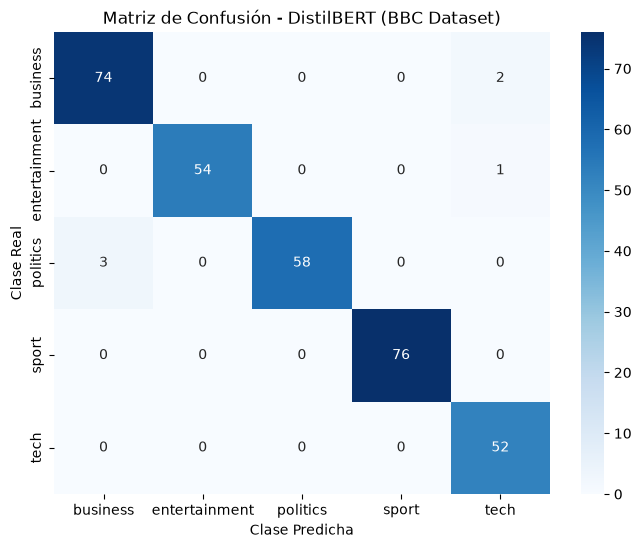

In [26]:
y_true_db, y_pred_db, probs_db = predecir(model, test_loader)

report_db = classification_report(y_true_db, y_pred_db, target_names=le.classes_, digits=4)
print("Reporte de clasificación DistilBERT\n")
print(report_db)

conf_matrix_db = confusion_matrix(y_true_db, y_pred_db)
graficar_confusion(conf_matrix_db, 'Matriz de Confusión - DistilBERT (BBC Dataset)')

### Análisis de resultados

DistilBERT falla 6 de los 320 artículos de prueba, con accuracy de 0.9812 y F1 macro de 0.9810.

- sport es perfecta, con precisión, recall y F1 de 1.0000.
- entertainment tiene el siguiente mejor F1, 0.9908.
- politics tiene precisión de 1.0000 pero recall de 0.9508, porque 3 artículos de política se clasifican como business.
- business tiene el F1 más bajo, 0.9673, seguida de tech con 0.9720. tech tiene recall de 1.0000 pero precisión de 0.9455, porque recibe dos artículos de business y uno de entertainment.

### Análisis cualitativo del modelo

Artículos de prueba mal clasificados y primeros aciertos, con la probabilidad que el modelo asignó a su predicción.

In [27]:
errores_db = np.where(y_true_db != y_pred_db)[0]
aciertos_db = np.where(y_true_db == y_pred_db)[0][:5]

print("Artículos mal clasificados por DistilBERT")
display(tabla_predicciones(errores_db, y_true_db, y_pred_db, probs_db, X_test['text']))
print("Primeros aciertos")
display(tabla_predicciones(aciertos_db, y_true_db, y_pred_db, probs_db, X_test['text']))

Artículos mal clasificados por DistilBERT


,Título,Real,Predicha,Probabilidad
63,Making your office work for you,business,tech,0.966
109,UK firms 'embracing e-commerce',politics,business,0.950
173,US casino 'tricks' face ban in UK,politics,business,0.871
226,Card fraudsters 'targeting web',business,tech,0.932
254,New media battle for Bafta awards,entertainment,tech,0.877
315,BAA support ahead of court battle,politics,business,0.918


Primeros aciertos


,Título,Real,Predicha,Probabilidad
0,Ferguson hails Man Utd's resolve,sport,sport,0.983
1,English clubs make Euro history,sport,sport,0.982
2,Hanks greeted at wintry premiere,entertainment,entertainment,0.978
3,Britons growing 'digitally obese',tech,tech,0.977
4,SA unveils 'more for all' budget,business,business,0.984


Los 6 errores son noticias que mezclan temas. Tres artículos de política sobre comercio electrónico, casinos y aeropuertos se clasifican como business porque giran alrededor de empresas. Dos artículos de negocios, sobre oficinas y sobre fraude con tarjetas en internet, y uno de entretenimiento sobre premios a sitios web se clasifican como tech. Sus probabilidades van de 0.871 a 0.966.

### Justificación de la elección del modelo

DistilBERT [Sanh et al., 2019](https://arxiv.org/abs/1910.01108) es una versión destilada de BERT con 40 % menos parámetros, 60 % más rápida, y que conserva el 97 % de su desempeño en GLUE. Sus 6 bloques permiten ajustar el modelo completo en pocos minutos en una GPU de consumo. La autoatención relaciona todas las palabras del artículo en paralelo, y los pesos preentrenados `distilbert-base-uncased` aportan un conocimiento general del inglés que el fine-tuning adapta a las 5 categorías.

### Justificación de las capas de clasificación

La clasificación usa el vector final del token [CLS], de 768 dimensiones. DistilBERT se preentrenó sin la tarea de predicción de la siguiente oración, así que este vector aprende a resumir el artículo durante el fine-tuning.

Sobre ese vector se añade una capa lineal de 768 a 768 con ReLU, que da una transformación no lineal propia de la tarea, un Dropout de 0.2 que reduce el sobreajuste con solo 1488 artículos de entrenamiento, y una capa lineal de 768 a 5 que produce un logit por categoría.

Cada artículo pertenece a una sola categoría, así que la salida usa softmax, que reparte una probabilidad total de 1 entre las 5 clases. Una sigmoide por clase correspondería a un problema multi-etiqueta.

## Modelo RoBERTa

Como segundo modelo se usa `roberta-base` [Liu et al., 2019](https://arxiv.org/abs/1907.11692), para comparar DistilBERT con un modelo más grande. RoBERTa mantiene la arquitectura de BERT base, con 12 bloques y 125 millones de parámetros, y mejora su preentrenamiento con más datos y más tiempo de entrenamiento, enmascaramiento dinámico, sin la tarea de siguiente oración y con un vocabulario BPE a nivel de bytes de 50 265 tokens que no genera tokens desconocidos. Su tokenizador distingue mayúsculas, por eso el texto no se pasa a minúsculas.

### Instanciación del modelo RoBERTa

In [28]:
roberta_tokenizer = RobertaTokenizer.from_pretrained('roberta-base')

seed_everything(SEED)
roberta_model = RobertaForSequenceClassification.from_pretrained(
    'roberta-base', num_labels=5, attn_implementation='eager').to(device)

Loading weights: 100%|██████████| 197/197 [00:00<00:00, 925.81it/s]
[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [29]:
print(roberta_model)

RobertaForSequenceClassification(
  (roberta): RobertaModel(
    (embeddings): RobertaEmbeddings(
      (word_embeddings): Embedding(50265, 768, padding_idx=1)
      (token_type_embeddings): Embedding(1, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-05, elementwise_affine=True, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
      (position_embeddings): Embedding(514, 768, padding_idx=1)
    )
    (encoder): RobertaEncoder(
      (layer): ModuleList(
        (0-11): 12 x RobertaLayer(
          (attention): RobertaAttention(
            (self): RobertaSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): RobertaSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
  

### Visualización del modelo

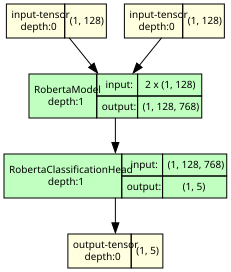

In [30]:
roberta_model.eval()

dummy_input_ids_rob = torch.randint(0, roberta_model.config.vocab_size, (1, 128), dtype=torch.long).to(device)
dummy_attention_mask_rob = torch.ones((1, 128), dtype=torch.long).to(device)

roberta_graph = draw_graph(
    roberta_model,
    input_data=(dummy_input_ids_rob, dummy_attention_mask_rob),
    expand_nested=True,
    graph_name='Roberta_BBC',
    depth=1
)

roberta_graph.visual_graph.render(filename=os.path.join(FIG_DIR, 'roberta_architecture'), format='svg', cleanup=True)
roberta_graph.visual_graph

### Resumen del flujo dimensional del modelo

| Componente | Salida | Función |
| :--- | :--- | :--- |
| Entrada | B × 512 | input_ids y máscara de atención |
| RoBERTa, 12 bloques | B × 512 × 768 | Representación contextual de cada token |
| Token &lt;s&gt; | B × 768 | Resumen del artículo |
| Dropout, dense, tanh y Dropout | B × 768 | Transformación no lineal y regularización |
| out_proj | B × 5 | Logits de las 5 categorías |
| Softmax | B × 5 | Probabilidad de cada categoría |

### Preprocesamiento para RoBERTa

Se usa la misma limpieza y la misma longitud máxima que con DistilBERT, sin pasar a minúsculas.

In [31]:
X_train_ids_rob, train_masks_rob = preprocess_dataset(X_train['text'], roberta_tokenizer, minusculas=False)
X_val_ids_rob, val_masks_rob = preprocess_dataset(X_val['text'], roberta_tokenizer, minusculas=False)
X_test_ids_rob, test_masks_rob = preprocess_dataset(X_test['text'], roberta_tokenizer, minusculas=False)

print("Train:", tuple(X_train_ids_rob.shape), "Val:", tuple(X_val_ids_rob.shape), "Test:", tuple(X_test_ids_rob.shape))
print(f"Artículos de entrenamiento con más de 512 tokens: "
      f"{porcentaje_truncados(X_train['text'], roberta_tokenizer, minusculas=False):.1f} %")

train_loader_rob = crear_loader(X_train_ids_rob, train_masks_rob, y_train_encoded, shuffle=True)
val_loader_rob = crear_loader(X_val_ids_rob, val_masks_rob, y_val_encoded)
test_loader_rob = crear_loader(X_test_ids_rob, test_masks_rob, y_test_encoded)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (562 > 512). Running this sequence through the model will result in indexing errors


Train: (1488, 512) Val: (319, 512) Test: (320, 512)
Artículos de entrenamiento con más de 512 tokens: 25.2 %


### Entrenamiento del modelo RoBERTa

In [32]:
seed_everything(SEED)
history_roberta = entrenar_modelo(roberta_model, train_loader_rob, val_loader_rob)

Época 1/4 - loss: 0.7918 - val_loss: 0.0565 - mejor modelo
Época 2/4 - loss: 0.0913 - val_loss: 0.0593
Época 3/4 - loss: 0.0405 - val_loss: 0.0419 - mejor modelo
Época 4/4 - loss: 0.0190 - val_loss: 0.0324 - mejor modelo
Entrenamiento finalizado en 119.7 s


### Pérdida a lo largo del entrenamiento

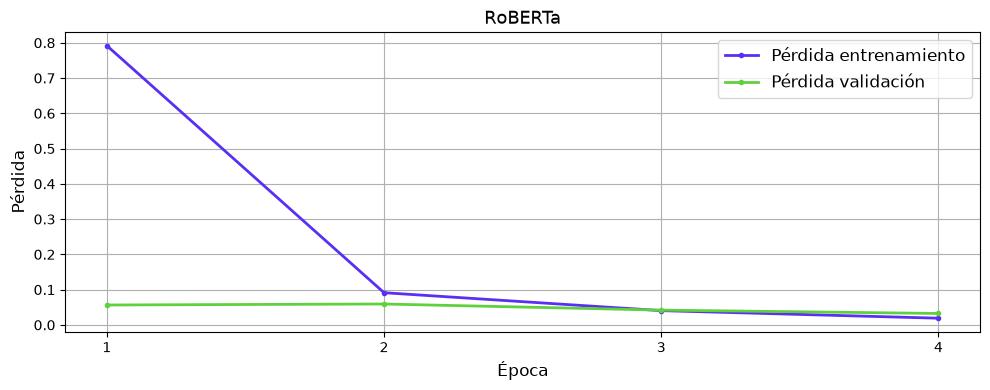

In [33]:
visualization_history(history_roberta, 'RoBERTa')

La pérdida de validación sube levemente en la segunda época, a 0.0593, y luego vuelve a bajar hasta 0.0324 en la cuarta, que es la época que se conserva.

### Evaluación del modelo con conjunto de prueba

Reporte de clasificación RoBERTa

               precision    recall  f1-score   support

     business     0.9867    0.9737    0.9801        76
entertainment     0.9818    0.9818    0.9818        55
     politics     0.9831    0.9508    0.9667        61
        sport     1.0000    1.0000    1.0000        76
         tech     0.9455    1.0000    0.9720        52

     accuracy                         0.9812       320
    macro avg     0.9794    0.9813    0.9801       320
 weighted avg     0.9816    0.9812    0.9812       320



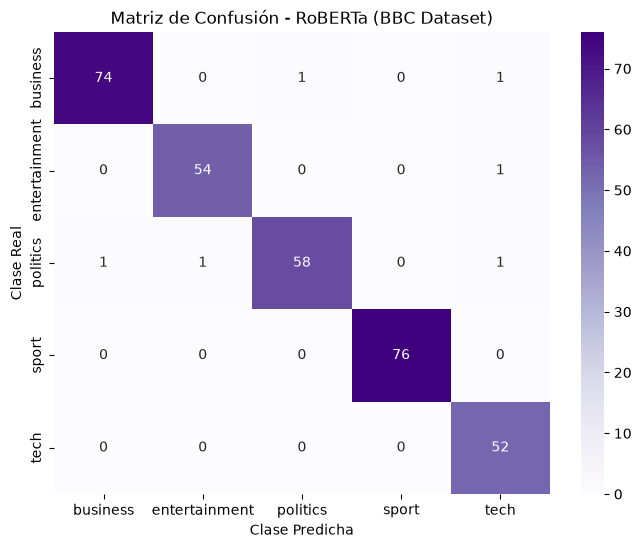

In [34]:
y_true_ra, y_pred_ra, probs_ra = predecir(roberta_model, test_loader_rob)

report_ra = classification_report(y_true_ra, y_pred_ra, target_names=le.classes_, digits=4)
print("Reporte de clasificación RoBERTa\n")
print(report_ra)

conf_matrix_ra = confusion_matrix(y_true_ra, y_pred_ra)
graficar_confusion(conf_matrix_ra, 'Matriz de Confusión - RoBERTa (BBC Dataset)', cmap='Purples')

### Análisis de resultados

RoBERTa también falla 6 de los 320 artículos, con accuracy de 0.9812 y F1 macro de 0.9801 en esta semilla.

- sport vuelve a ser perfecta.
- business mejora frente a DistilBERT, con F1 de 0.9801.
- entertainment baja a 0.9818, porque recibe un artículo de política y pierde uno que se clasifica como tech.
- politics tiene el F1 más bajo, 0.9667, con recall de 0.9508, porque sus artículos se reparten entre business, entertainment y tech.
- tech mantiene precisión de 0.9455 porque recibe un artículo de business, uno de entertainment y uno de politics.

### Análisis cualitativo del modelo

In [35]:
errores_ra = np.where(y_true_ra != y_pred_ra)[0]
aciertos_ra = np.where(y_true_ra == y_pred_ra)[0][:5]

print("Artículos mal clasificados por RoBERTa")
display(tabla_predicciones(errores_ra, y_true_ra, y_pred_ra, probs_ra, X_test['text']))
print("Primeros aciertos")
display(tabla_predicciones(aciertos_ra, y_true_ra, y_pred_ra, probs_ra, X_test['text']))

Artículos mal clasificados por RoBERTa


,Título,Real,Predicha,Probabilidad
63,Making your office work for you,business,tech,0.983
109,UK firms 'embracing e-commerce',politics,tech,0.789
180,Telegraph newspapers axe 90 jobs,business,politics,0.480
254,New media battle for Bafta awards,entertainment,tech,0.939
309,'Hitler' row over Welsh arts cash,politics,entertainment,0.765
315,BAA support ahead of court battle,politics,business,0.931


Primeros aciertos


,Título,Real,Predicha,Probabilidad
0,Ferguson hails Man Utd's resolve,sport,sport,0.995
1,English clubs make Euro history,sport,sport,0.995
2,Hanks greeted at wintry premiere,entertainment,entertainment,0.994
3,Britons growing 'digitally obese',tech,tech,0.992
4,SA unveils 'more for all' budget,business,business,0.994


Los errores de RoBERTa también mezclan temas. Son una columna sobre oficinas, un estudio del gobierno sobre comercio electrónico, el recorte de empleos en un periódico, los premios Bafta a sitios web, una polémica sobre la financiación de las artes en Gales y el apoyo de un operador de aeropuertos a un plan del gobierno. Cuatro de ellos también los falla DistilBERT. Tres errores tienen probabilidad menor a 0.9, con 0.789, 0.480 y 0.765, lo que muestra que el modelo duda en esos casos.

## Comparación de métricas de los dos modelos

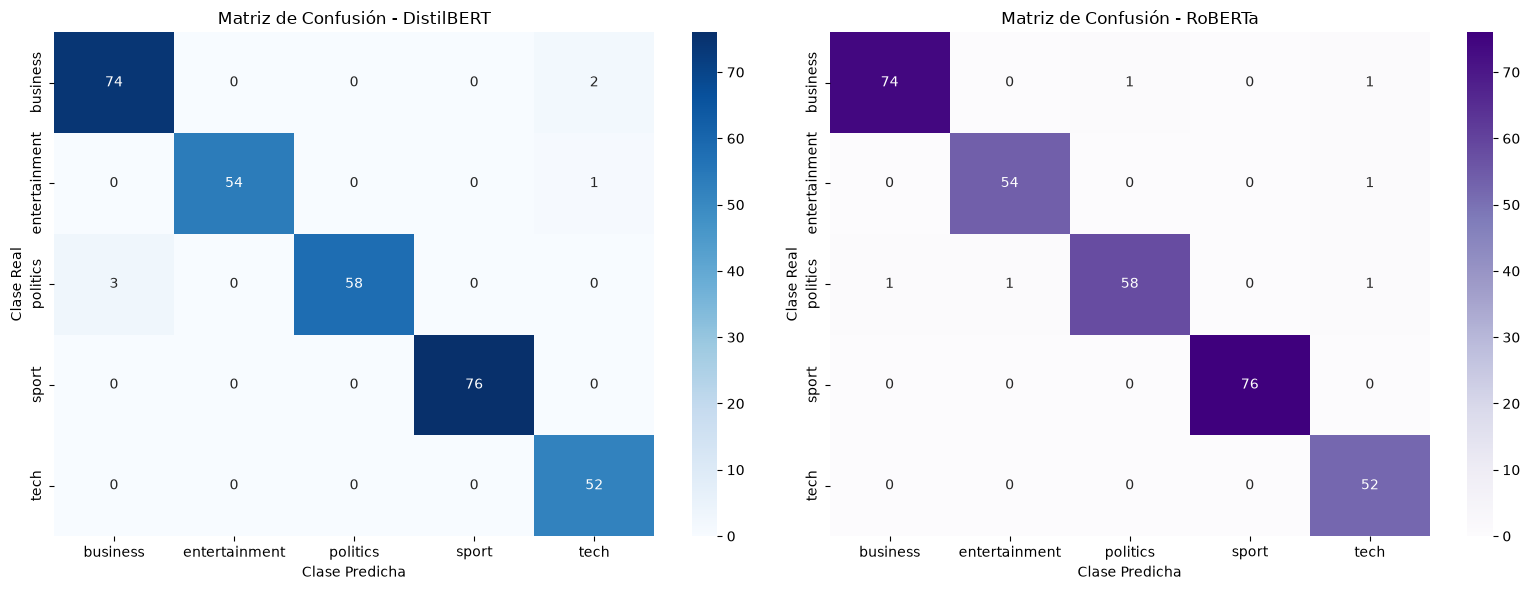

,Precisión (DistilBERT),Precisión (RoBERTa),Recall (DistilBERT),Recall (RoBERTa),F1-Score (DistilBERT),F1-Score (RoBERTa)
Categoría,,,,,,
business,0.9610,0.9867,0.9737,0.9737,0.9673,0.9801
entertainment,1.0000,0.9818,0.9818,0.9818,0.9908,0.9818
politics,1.0000,0.9831,0.9508,0.9508,0.9748,0.9667
sport,1.0000,1.0000,1.0000,1.0000,1.0000,1.0000
tech,0.9455,0.9455,1.0000,1.0000,0.9720,0.9720


\begin{table}
\caption{Comparativa de métricas por categoría entre DistilBERT y RoBERTa.}
\label{tab:comparacion_modelos}
\begin{tabular}{lrrrrrr}
\toprule
 & Precisión (DistilBERT) & Precisión (RoBERTa) & Recall (DistilBERT) & Recall (RoBERTa) & F1-Score (DistilBERT) & F1-Score (RoBERTa) \\
Categoría &  &  &  &  &  &  \\
\midrule
business & 0.9610 & 0.9867 & 0.9737 & 0.9737 & 0.9673 & 0.9801 \\
entertainment & 1.0000 & 0.9818 & 0.9818 & 0.9818 & 0.9908 & 0.9818 \\
politics & 1.0000 & 0.9831 & 0.9508 & 0.9508 & 0.9748 & 0.9667 \\
sport & 1.0000 & 1.0000 & 1.0000 & 1.0000 & 1.0000 & 1.0000 \\
tech & 0.9455 & 0.9455 & 1.0000 & 1.0000 & 0.9720 & 0.9720 \\
\bottomrule
\end{tabular}
\end{table}



In [36]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(conf_matrix_db, annot=True, fmt='d', cmap='Blues',
            xticklabels=le.classes_, yticklabels=le.classes_, ax=axes[0])
axes[0].set_title('Matriz de Confusión - DistilBERT')
axes[0].set_xlabel('Clase Predicha')
axes[0].set_ylabel('Clase Real')

sns.heatmap(conf_matrix_ra, annot=True, fmt='d', cmap='Purples',
            xticklabels=le.classes_, yticklabels=le.classes_, ax=axes[1])
axes[1].set_title('Matriz de Confusión - RoBERTa')
axes[1].set_xlabel('Clase Predicha')
axes[1].set_ylabel('Clase Real')

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'matrices_confusion.png'), dpi=300, bbox_inches='tight')
plt.show()

rep_db = classification_report(y_true_db, y_pred_db, target_names=le.classes_, output_dict=True)
rep_ra = classification_report(y_true_ra, y_pred_ra, target_names=le.classes_, output_dict=True)

comparison_rows = []
for cat in le.classes_:
    comparison_rows.append({
        'Categoría': cat,
        'Precisión (DistilBERT)': rep_db[cat]['precision'],
        'Precisión (RoBERTa)': rep_ra[cat]['precision'],
        'Recall (DistilBERT)': rep_db[cat]['recall'],
        'Recall (RoBERTa)': rep_ra[cat]['recall'],
        'F1-Score (DistilBERT)': rep_db[cat]['f1-score'],
        'F1-Score (RoBERTa)': rep_ra[cat]['f1-score'],
    })

df_reports_comparison = pd.DataFrame(comparison_rows).set_index('Categoría')
display(df_reports_comparison.round(4))

print(df_reports_comparison.to_latex(
    float_format='%.4f',
    caption='Comparativa de métricas por categoría entre DistilBERT y RoBERTa.',
    label='tab:comparacion_modelos'
))

### Métricas globales

In [37]:
metrics_global = {
    'Métrica Global': ['Accuracy', 'F1-Score (Macro Avg)', 'F1-Score (Weighted Avg)'],
    'DistilBERT': [rep_db['accuracy'], rep_db['macro avg']['f1-score'], rep_db['weighted avg']['f1-score']],
    'RoBERTa': [rep_ra['accuracy'], rep_ra['macro avg']['f1-score'], rep_ra['weighted avg']['f1-score']],
}

df_global_comparison = pd.DataFrame(metrics_global).set_index('Métrica Global')
display(df_global_comparison.round(4))
print(df_global_comparison.to_latex(float_format='%.4f'))

,DistilBERT,RoBERTa
Métrica Global,,
Accuracy,0.9812,0.9812
F1-Score (Macro Avg),0.9810,0.9801
F1-Score (Weighted Avg),0.9813,0.9812


\begin{tabular}{lrr}
\toprule
 & DistilBERT & RoBERTa \\
Métrica Global &  &  \\
\midrule
Accuracy & 0.9812 & 0.9812 \\
F1-Score (Macro Avg) & 0.9810 & 0.9801 \\
F1-Score (Weighted Avg) & 0.9813 & 0.9812 \\
\bottomrule
\end{tabular}



## Comparación de complejidad de los modelos

In [38]:
def count_parameters(model):
    """Calcula el total de parámetros y los parámetros entrenables del modelo."""
    total_params = sum(p.numel() for p in model.parameters())
    trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
    
    print(f"• Parámetros totales: {total_params:,}")
    print(f"• Parámetros entrenables: {trainable_params:,}")
    return total_params

print("--- RoBERTa ---")
roberta_params = count_parameters(roberta_model)

print("\n--- DistilBERT ---")
distilbert_params = count_parameters(model)

--- RoBERTa ---
• Parámetros totales: 124,649,477
• Parámetros entrenables: 124,649,477

--- DistilBERT ---
• Parámetros totales: 66,957,317
• Parámetros entrenables: 66,957,317


### Variación con la semilla

Con 320 artículos de prueba, uno o dos artículos bastan para cambiar la comparación. Para saber si la diferencia entre los modelos es estable, cada uno se entrena con dos semillas adicionales, 1 y 2, con el mismo procedimiento. La semilla cambia la inicialización de la cabeza de clasificación, el orden de los lotes y el dropout.

In [39]:
SEMILLAS_EXTRA = [1, 2]
hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()

configs = {
    'DistilBERT': (DistilBertForSequenceClassification, 'distilbert-base-uncased', train_loader, val_loader, test_loader),
    'RoBERTa': (RobertaForSequenceClassification, 'roberta-base', train_loader_rob, val_loader_rob, test_loader_rob),
}


def registrar(nombre, semilla, yt, yp, tiempo):
    """Agrega las métricas globales y el F1 por categoría de una corrida."""
    rep = classification_report(yt, yp, target_names=le.classes_, output_dict=True)
    filas.append({'Modelo': nombre, 'Semilla': semilla, 'Accuracy': rep['accuracy'],
                  'F1 macro': rep['macro avg']['f1-score'], 'Tiempo (s)': tiempo})
    for cat in le.classes_:
        filas_clase.append({'Modelo': nombre, 'Semilla': semilla, 'Categoría': cat, 'F1': rep[cat]['f1-score']})


filas, filas_clase = [], []
registrar('DistilBERT', SEED, y_true_db, y_pred_db, history['tiempo'])
registrar('RoBERTa', SEED, y_true_ra, y_pred_ra, history_roberta['tiempo'])

for nombre, (clase, pesos, tr_loader, va_loader, te_loader) in configs.items():
    for semilla in SEMILLAS_EXTRA:
        seed_everything(semilla)
        modelo_semilla = clase.from_pretrained(pesos, num_labels=5, attn_implementation='eager').to(device)
        seed_everything(semilla)
        hist = entrenar_modelo(modelo_semilla, tr_loader, va_loader, verbose=False)
        yt, yp, _ = predecir(modelo_semilla, te_loader)
        registrar(nombre, semilla, yt, yp, hist['tiempo'])
        del modelo_semilla
        torch.cuda.empty_cache()

resultados_semillas = pd.DataFrame(filas).sort_values(['Modelo', 'Semilla']).reset_index(drop=True)
f1_por_clase = pd.DataFrame(filas_clase)
display(resultados_semillas.round(4))

parametros = {'DistilBERT': sum(p.numel() for p in model.parameters()),
              'RoBERTa': sum(p.numel() for p in roberta_model.parameters())}
print({k: f'{v / 1e6:.1f} M' for k, v in parametros.items()})

resumen_semillas = resultados_semillas.groupby('Modelo')[['Accuracy', 'F1 macro', 'Tiempo (s)']].agg(['mean', 'std'])

resumen_clase = f1_por_clase.groupby(['Categoría', 'Modelo'])['F1'].agg(['mean', 'std']).unstack()

,Modelo,Semilla,Accuracy,F1 macro,Tiempo (s)
0,DistilBERT,1,0.9812,0.9805,59.7191
1,DistilBERT,2,0.9781,0.9772,60.1643
2,DistilBERT,42,0.9812,0.9810,61.6990
3,RoBERTa,1,0.9781,0.9772,125.5274
4,RoBERTa,2,0.9875,0.9858,135.3128
5,RoBERTa,42,0.9812,0.9801,119.6807


{'DistilBERT': '67.0 M', 'RoBERTa': '124.6 M'}


### Tablas resumen de la comparación

Valores de prueba de la semilla 42 y media ± desviación estándar en las tres semillas.

In [40]:
def media_std(serie):
    return f'{serie.mean():.4f} ± {serie.std():.4f}'

tabla_comparativa = pd.DataFrame({
    nombre: {
        'Parámetros (millones)': f'{parametros[nombre] / 1e6:.1f}',
        'Bloques Transformer': str(mdl.config.num_hidden_layers if nombre == 'RoBERTa' else mdl.config.n_layers),
        'Accuracy semilla 42': f"{resultados_semillas.query('Modelo == @nombre and Semilla == @SEED')['Accuracy'].iloc[0]:.4f}",
        'F1 macro semilla 42': f"{resultados_semillas.query('Modelo == @nombre and Semilla == @SEED')['F1 macro'].iloc[0]:.4f}",
        'Accuracy 3 semillas': media_std(resultados_semillas.query('Modelo == @nombre')['Accuracy']),
        'F1 macro 3 semillas': media_std(resultados_semillas.query('Modelo == @nombre')['F1 macro']),
        'Tiempo de entrenamiento (s)': f"{resultados_semillas.query('Modelo == @nombre')['Tiempo (s)'].mean():.1f}",
    }
    for nombre, mdl in [('DistilBERT', model), ('RoBERTa', roberta_model)]
})
display(tabla_comparativa)

tabla_clase = pd.DataFrame({
    nombre: {cat: media_std(f1_por_clase.query('Modelo == @nombre and Categoría == @cat')['F1']) for cat in le.classes_}
    for nombre in ['DistilBERT', 'RoBERTa']
})
tabla_clase.index.name = 'F1 por categoría'
display(tabla_clase)

,DistilBERT,RoBERTa
Parámetros (millones),67.0,124.6
Bloques Transformer,6,12
Accuracy semilla 42,0.9812,0.9812
F1 macro semilla 42,0.9810,0.9801
Accuracy 3 semillas,0.9802 ± 0.0018,0.9823 ± 0.0048
F1 macro 3 semillas,0.9796 ± 0.0020,0.9810 ± 0.0044
Tiempo de entrenamiento (s),60.5,126.8


,DistilBERT,RoBERTa
F1 por categoría,,
business,0.9694 ± 0.0037,0.9801 ± 0.0132
entertainment,0.9848 ± 0.0052,0.9760 ± 0.0101
politics,0.9748 ± 0.0000,0.9806 ± 0.0128
sport,1.0000 ± 0.0000,1.0000 ± 0.0000
tech,0.9687 ± 0.0056,0.9686 ± 0.0055


RoBERTa tiene mayor accuracy media, 0.9823 ± 0.0048 frente a 0.9802 ± 0.0018, y mayor F1 macro medio, 0.9810 ± 0.0044 frente a 0.9796 ± 0.0020. También logra el mejor resultado individual, con accuracy de 0.9875 y F1 macro de 0.9858 en la semilla 2. A cambio varía más entre semillas y su entrenamiento tarda 117.3 s frente a 59.1 s de DistilBERT.

### Dónde funciona y dónde falla el modelo elegido

Se elige el modelo con mayor F1 macro promedio en las tres semillas. La figura resume el F1 por categoría de ambos modelos, la matriz de confusión del modelo elegido y la probabilidad que asigna a sus predicciones correctas e incorrectas.

Modelo elegido: RoBERTa


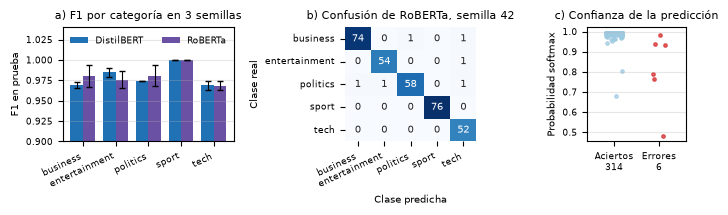

Probabilidad mediana en aciertos: 0.994, en errores: 0.860
Aciertos con probabilidad menor a 0.9: 2, errores con probabilidad menor a 0.9: 3


In [41]:
mejor = resumen_semillas[('F1 macro', 'mean')].idxmax()
cm_mejor, y_true_m, y_pred_m, probs_m = {
    'DistilBERT': (conf_matrix_db, y_true_db, y_pred_db, probs_db),
    'RoBERTa': (conf_matrix_ra, y_true_ra, y_pred_ra, probs_ra),
}[mejor]
print("Modelo elegido:", mejor)

colores = {'DistilBERT': '#2171b5', 'RoBERTa': '#6a51a3'}
# Tamaño final del ancho de página del informe, para que la letra se lea sin reducirla
fig, axes = plt.subplots(1, 3, figsize=(7.0, 2.25), gridspec_kw={'width_ratios': [1.3, 1, 0.75]})
TT, TL, TK = 8, 7, 6.5

# a) F1 por categoría, media y desviación estándar en tres semillas
x = np.arange(len(le.classes_))
ancho = 0.38
for k, nombre in enumerate(['DistilBERT', 'RoBERTa']):
    medias = resumen_clase[('mean', nombre)].reindex(le.classes_)
    desv = resumen_clase[('std', nombre)].reindex(le.classes_)
    axes[0].bar(x + (k - 0.5) * ancho, medias, ancho, yerr=desv, capsize=2, error_kw={'lw': 0.8},
                color=colores[nombre], label=nombre)
axes[0].set_xticks(x)
axes[0].set_xticklabels(le.classes_, fontsize=TK, rotation=25, ha='right')
axes[0].tick_params(axis='y', labelsize=TK)
axes[0].set_ylim(0.90, 1.04)
axes[0].set_ylabel('F1 en prueba', fontsize=TL)
axes[0].set_title('a) F1 por categoría en 3 semillas', fontsize=TT)
axes[0].legend(fontsize=TK, loc='upper center', bbox_to_anchor=(0.5, 1.0), ncol=2, frameon=False)
axes[0].grid(axis='y', alpha=0.3)

# b) Matriz de confusión del modelo elegido
sns.heatmap(cm_mejor, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[1],
            xticklabels=le.classes_, yticklabels=le.classes_, annot_kws={'fontsize': TL})
axes[1].set_xlabel('Clase predicha', fontsize=TL)
axes[1].set_ylabel('Clase real', fontsize=TL)
axes[1].tick_params(labelsize=TK)
axes[1].set_xticklabels(le.classes_, rotation=25, ha='right')
axes[1].set_title(f'b) Confusión de {mejor}, semilla 42', fontsize=TT)

# c) Probabilidad de la clase predicha en aciertos y errores
p_pred = probs_m[np.arange(len(y_pred_m)), y_pred_m]
grupos = [p_pred[y_true_m == y_pred_m], p_pred[y_true_m != y_pred_m]]
rng = np.random.default_rng(0)
for k, (valores, color) in enumerate(zip(grupos, ['#9ecae1', '#d62728'])):
    axes[2].scatter(k + rng.uniform(-0.18, 0.18, len(valores)), valores, s=6, alpha=0.7, color=color)
axes[2].set_xticks([0, 1])
axes[2].set_xticklabels([f'Aciertos\n{len(grupos[0])}', f'Errores\n{len(grupos[1])}'], fontsize=TK)
axes[2].tick_params(axis='y', labelsize=TK)
axes[2].set_xlim(-0.6, 1.6)
axes[2].set_ylabel('Probabilidad softmax', fontsize=TL)
axes[2].set_title('c) Confianza de la predicción', fontsize=TT)
axes[2].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, 'resultados_modelo_elegido.png'), dpi=300, bbox_inches='tight')
plt.show()

print(f"Probabilidad mediana en aciertos: {np.median(grupos[0]):.3f}, en errores: {np.median(grupos[1]):.3f}")
print(f"Aciertos con probabilidad menor a 0.9: {(grupos[0] < 0.9).sum()}, errores con probabilidad menor a 0.9: {(grupos[1] < 0.9).sum()}")

Se elige RoBERTa por su mayor F1 macro medio. Supera a DistilBERT en business y politics, DistilBERT es mejor en entertainment, empatan en tech y ambos son perfectos en sport. La probabilidad mediana de RoBERTa es 0.994 en los aciertos y 0.860 en los errores, y tres de sus seis errores quedan por debajo de 0.9.

### Mapas de atención

Se compara a qué palabras atienden los dos modelos en el mismo fragmento de un artículo de prueba. Primero se muestra una cabeza individual de cada modelo.

In [42]:
def plot_attention_head(model, tokenizer, text, device, layer_idx=-1, head_idx=0, nombre_archivo=None):
    """Mapa de atención de una cabeza en una capa, con el texto limpiado igual que en el entrenamiento."""
    text = limpiar_texto(text, minusculas=(model.config.model_type == 'distilbert'))
    inputs = tokenizer(text, return_tensors='pt', truncation=True, max_length=512).to(device)

    model.eval()
    with torch.no_grad():
        outputs = model(**inputs, output_attentions=True)

    n_capas = len(outputs.attentions)
    attention_matrix = outputs.attentions[layer_idx][0, head_idx].cpu().numpy()
    tokens = tokenizer.convert_ids_to_tokens(inputs['input_ids'][0])

    plt.figure(figsize=(10, 8))
    sns.heatmap(attention_matrix, cmap='Blues', xticklabels=tokens, yticklabels=tokens, vmax=0.15, cbar=True)
    plt.xticks(rotation=45, ha='right', fontsize=9)
    plt.yticks(fontsize=9)
    plt.xlabel('Tokens Destino (Key)', fontsize=11)
    plt.ylabel('Tokens Origen (Query)', fontsize=11)
    plt.title(f'Mapa de Atención, capa {layer_idx % n_capas + 1} de {n_capas}, cabeza {head_idx + 1}', fontsize=13)
    plt.tight_layout()
    if nombre_archivo:
        plt.savefig(os.path.join(FIG_DIR, nombre_archivo), dpi=300, bbox_inches='tight')
    plt.show()

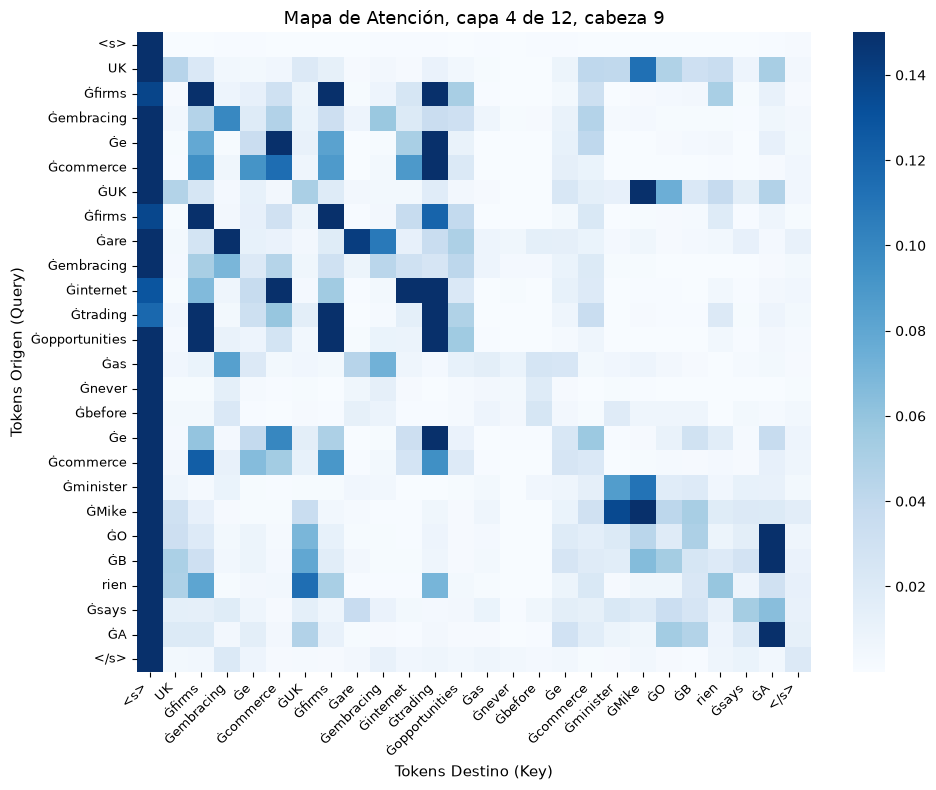

In [73]:
# Primeras 20 palabras del primer artículo de prueba
indice_elegido = 109
ejemplo_texto = str(X_test['text'].iloc[indice_elegido])
ejemplo_texto_corto = " ".join(ejemplo_texto.split()[:20])

plot_attention_head(roberta_model, roberta_tokenizer, ejemplo_texto_corto, device,
                    layer_idx=3, head_idx=8, nombre_archivo='atencion_roberta_cabeza.png')

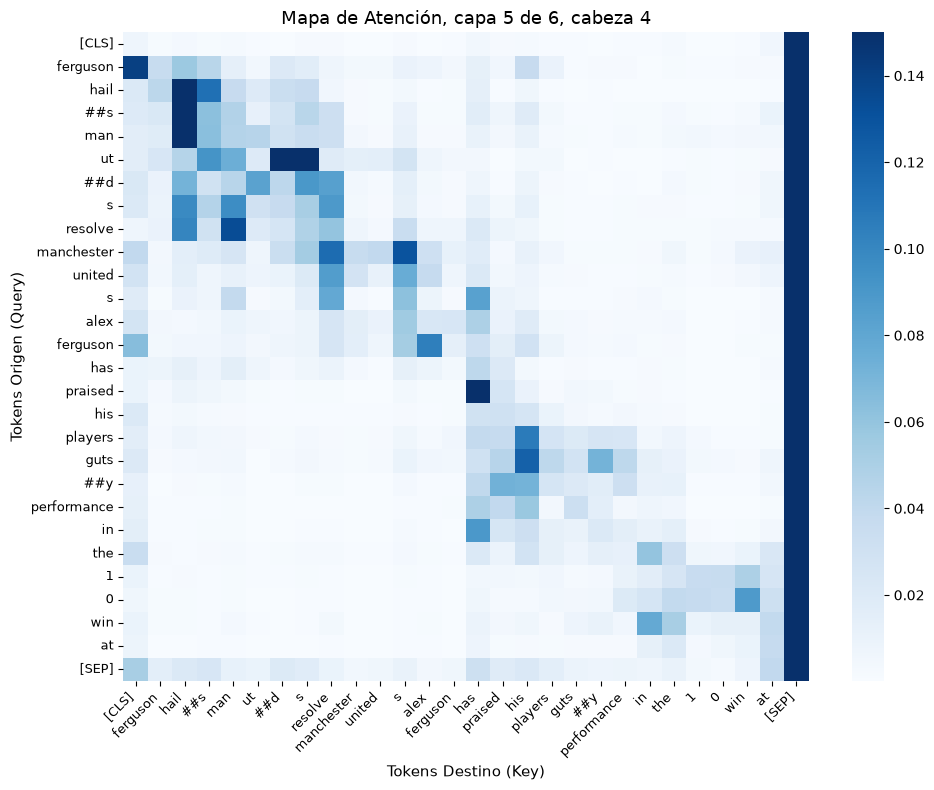

In [44]:
plot_attention_head(model, tokenizer, ejemplo_texto_corto, device,
                    layer_idx=4, head_idx=3, nombre_archivo='atencion_distilbert_cabeza.png')

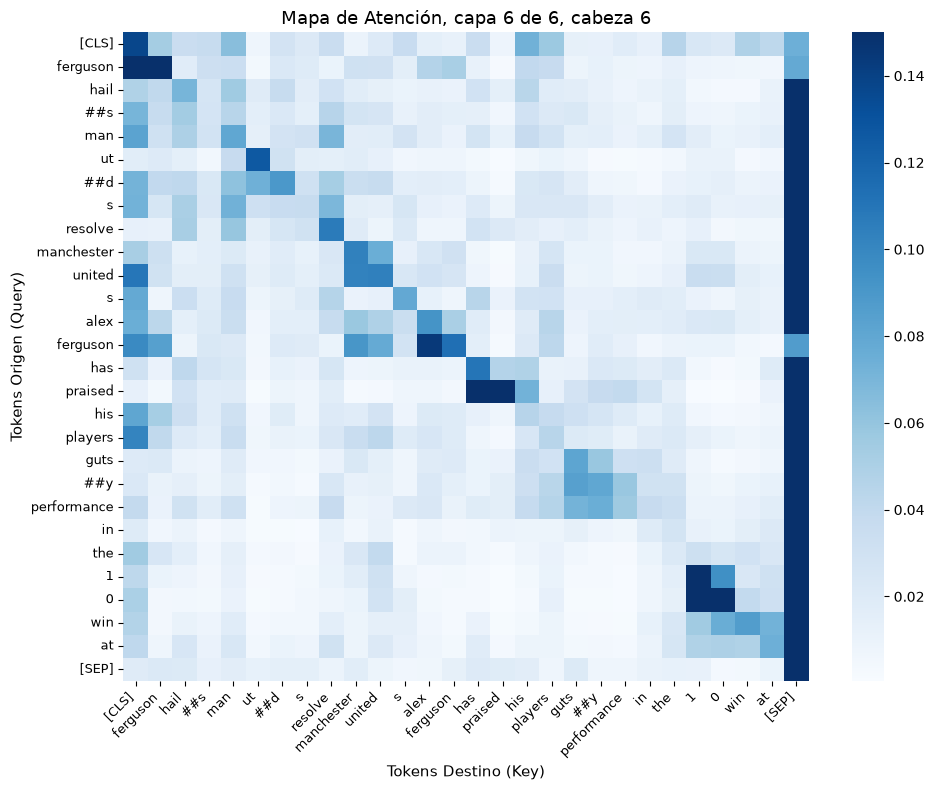

In [45]:
plot_attention_head(model, tokenizer, ejemplo_texto_corto, device,
                    layer_idx=-1, head_idx=5, nombre_archivo='atencion_distilbert_ultima_capa.png')

### Comparación de mapas de atención entre DistilBERT y RoBERTa

Para comparar los modelos se promedian las cabezas de la última capa y los subtokens se agrupan en palabras. Se excluyen los tokens especiales, que concentran buena parte de la atención, y cada fila se renormaliza para que sume 1.

La segunda figura muestra a qué palabras atiende el token de clasificación, [CLS] en DistilBERT y &lt;s&gt; en RoBERTa, cuyo vector final es el que usa la cabeza de clasificación. La atención indica en qué se fija el modelo, pero no explica por sí sola la predicción.

In [ ]:
def atencion_por_palabra(model, tokenizer, text, device, layer_idx=-1):
    """Atención de una capa promediada sobre sus cabezas y agrupada por palabra.
    Las columnas de subtokens de una misma palabra se suman y las filas se promedian.
    Retorna las palabras, la matriz palabra-palabra, la atención del token de clasificación por palabra,
    la fracción de esa atención que va a tokens especiales y el número de capas."""
    text = limpiar_texto(text, minusculas=(model.config.model_type == 'distilbert'))
    enc = tokenizer(text, return_tensors='pt', truncation=True, max_length=512)
    word_ids = enc.word_ids(0)  # None corresponde a tokens especiales

    model.eval()
    with torch.no_grad():
        outputs = model(input_ids=enc['input_ids'].to(device),
                        attention_mask=enc['attention_mask'].to(device),
                        output_attentions=True)

    n_capas = len(outputs.attentions)
    att = outputs.attentions[layer_idx][0].mean(dim=0).cpu().numpy()

    # Matriz de pertenencia token-palabra, con los tokens especiales en cero
    n_palabras = max(w for w in word_ids if w is not None) + 1
    M = np.zeros((len(word_ids), n_palabras))
    for t, w in enumerate(word_ids):
        if w is not None:
            M[t, w] = 1.0
    palabras = [text[slice(*enc.word_to_chars(0, w))] for w in range(n_palabras)]

    att_palabras = (M.T @ (att @ M)) / M.sum(axis=0)[:, None]
    att_palabras = att_palabras / att_palabras.sum(axis=1, keepdims=True)

    # Atención del token de clasificación, posición 0, hacia cada palabra
    cls = att[0] @ M
    frac_especiales = 1.0 - cls.sum()
    cls = cls / cls.sum()

    return palabras, att_palabras, cls, frac_especiales, n_capas


def comparar_mapas_atencion(modelos, text, device, layer_idx=-1, top_k=10):
    """modelos es una lista de tuplas con nombre, modelo y tokenizador.
    layer_idx puede ser un entero (misma capa para todos) o una lista con una capa por modelo,
    en el mismo orden que modelos. Las capas se cuentan desde 0; -1 es la última.
    top_k es el número de palabras que se muestran en la figura 2."""
    if isinstance(layer_idx, int):
        layer_idx = [layer_idx] * len(modelos)
    if len(layer_idx) != len(modelos):
        raise ValueError('layer_idx debe tener una capa por cada modelo')

    resultados = []
    for (nombre, mdl, tok), capa_idx in zip(modelos, layer_idx):
        palabras, att, cls, frac_esp, n_capas = atencion_por_palabra(mdl, tok, text, device, capa_idx)
        resultados.append(dict(nombre=nombre, palabras=palabras, att=att, cls=cls,
                               frac_esp=frac_esp, capa=capa_idx % n_capas + 1, n_capas=n_capas))

    # Sufijo con las capas usadas, para no sobrescribir figuras de otras corridas
    sufijo = '_'.join(f"{r['nombre'].lower()}_c{r['capa']}" for r in resultados)

    # Figura 1, mapas palabra-palabra con la misma escala de color
    vmax = max(r['att'].max() for r in resultados)
    fig, axes = plt.subplots(1, len(resultados), figsize=(9 * len(resultados), 8.5))
    for ax, r in zip(np.atleast_1d(axes), resultados):
        sns.heatmap(r['att'], xticklabels=r['palabras'], yticklabels=r['palabras'], cmap='Blues',
                    vmin=0, vmax=vmax, square=True, ax=ax,
                    cbar_kws={'shrink': 0.75, 'label': 'Proporción de atención'})
        ax.set_title(f"{r['nombre']}, capa {r['capa']} de {r['n_capas']}, promedio de cabezas", fontsize=13)
        ax.set_xlabel('Palabra a la que se mira (Key)', fontsize=11)
        ax.set_ylabel('Palabra que mira (Query)', fontsize=11)
        ax.tick_params(axis='x', rotation=90, labelsize=9)
        ax.tick_params(axis='y', rotation=0, labelsize=9)
    fig.suptitle('Mapas de atención entre palabras sin tokens especiales', fontsize=15)
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f'mapas_atencion_{sufijo}.png'), dpi=300, bbox_inches='tight')
    plt.show()

    # Figura 2, solo las top_k palabras con más atención del token de clasificación
    fig, axes = plt.subplots(1, len(resultados), figsize=(6.5 * len(resultados), 0.5 * top_k + 2))
    xmax = max(r['cls'].max() for r in resultados) * 100 * 1.18
    for ax, r in zip(np.atleast_1d(axes), resultados):
        valores = r['cls'] * 100
        idx = np.argsort(valores)[::-1][:top_k]                  
        top_vals = valores[idx]
        etiquetas = [f"{r['palabras'][i]} ({i})" for i in idx]   # la posición distingue palabras repetidas
        y = np.arange(len(idx))
        ax.barh(y, top_vals, height=0.7, color='#2171b5')
        for yi, v in zip(y, top_vals):
            ax.text(v + xmax * 0.01, yi, f'{v:.1f}%', va='center', fontsize=9, color='#333333')
        ax.set_yticks(y)
        ax.set_yticklabels(etiquetas, fontsize=10)
        ax.invert_yaxis()                                         
        ax.set_xlim(0, xmax)
        ax.set_xlabel('% de la atención del token de clasificación', fontsize=11)
        ax.set_title(f"{r['nombre']}, capa {r['capa']} de {r['n_capas']}\n"
                     f"{r['frac_esp']:.0%} de la atención va a tokens especiales", fontsize=12)
        ax.grid(axis='x', color='#e5e5e5', linewidth=0.8)
        ax.set_axisbelow(True)
        ax.spines[['top', 'right']].set_visible(False)
    fig.suptitle(f'Top {top_k} palabras según la atención del token de clasificación', fontsize=15)
    plt.tight_layout()
    plt.savefig(os.path.join(FIG_DIR, f'atencion_cls_{sufijo}.png'), dpi=300, bbox_inches='tight')
    plt.show()

Categoría real del artículo: politics
Fragmento analizado: UK firms 'embracing e-commerce'

UK firms are embracing internet trading opportunities as never before, e-commerce minister Mike O'Brien says.

A government-commissioned study ranked the UK third in its world index of use of information and communication technology (ICT). The report suggests 69% of UK firms are now using broadband and that 30% of micro businesses are trading online. Mr O'Brien said UK businesses were sprinting forward in ICT use, but that there were more challenges ahead. The report, carried out independently by consultants Booz Allen Hamilton and HI Europe, placed the UK third behind Sweden and Ireland for business use of ICT.

It showed British business brought greater maturity to their ICT use, by using broadband in increased numbers, bringing ICT into their business plans and using new technologies such as voice activated programmes and desktop video conferences. Mr O'Brien said: "The increase in the propor

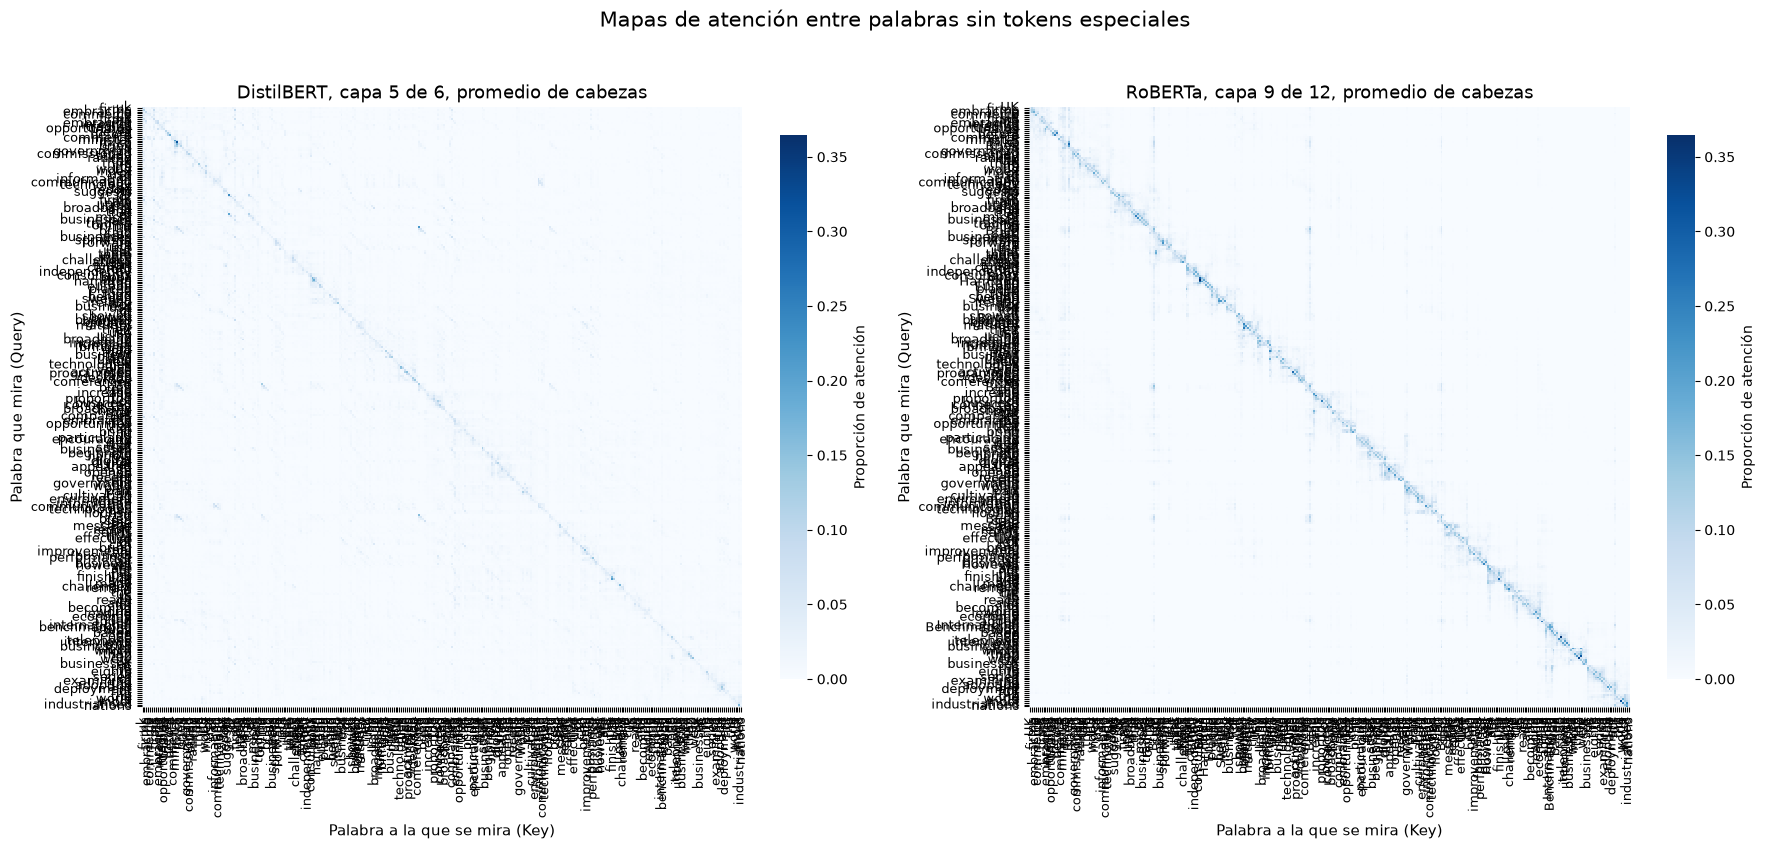

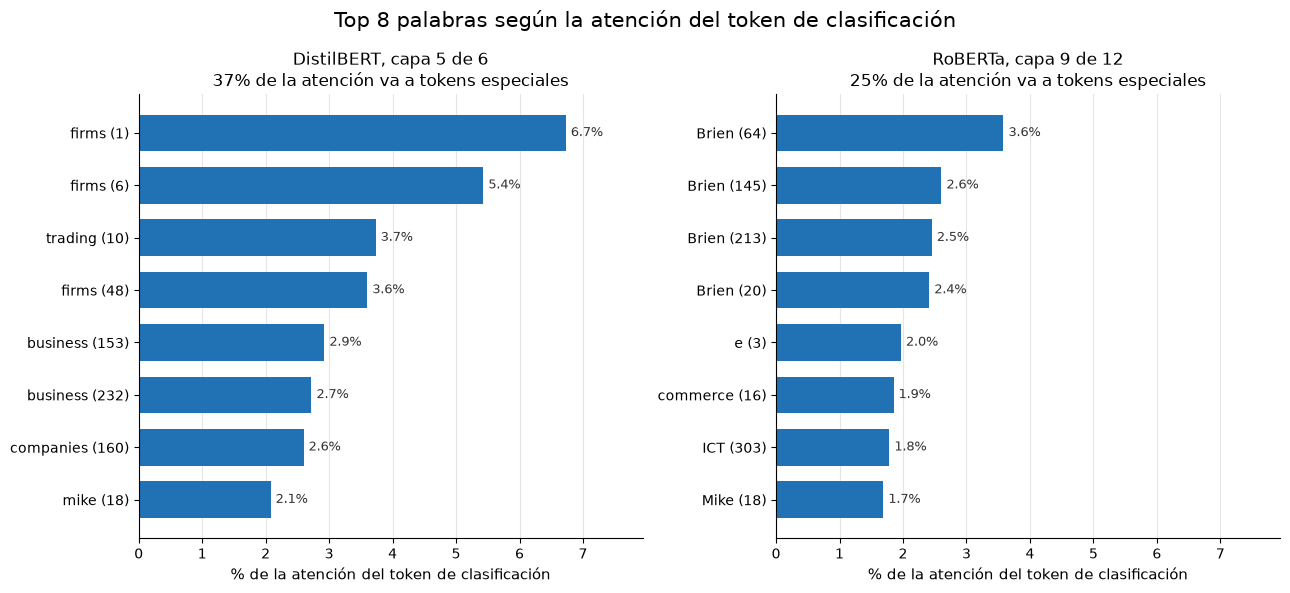

In [75]:
print(f"Categoría real del artículo: {le.classes_[y_test_encoded[indice_elegido]]}")
print(f"Fragmento analizado: {ejemplo_texto}")

comparar_mapas_atencion(
    modelos=[('DistilBERT', model, tokenizer), ('RoBERTa', roberta_model, roberta_tokenizer)],
    text=ejemplo_texto,
    device=device,
    layer_idx=[4, 8],   
    top_k=8,
)

Al observar los mapas de atención y en concreto la capa 5 de DiltilBERT vs la capa 9 de RoBERTa sobre un ejemplo mal calificado de RoBERTa se evidencia que le dio más atención a palabras como e-commerce lo cual pudo confundir con temáticas tecnológicas y pudo influir en su mala predicción. En contraposición, el modelo DistilBERT si pudo categorizarlo adecuadamente al prestarle más atención a labras como trading, business y companies las cuales estaban mucho mas presentes en el ejemplo y eran las más representativas para elegir "politics" como categoria adecuada.

## Conclusiones

- RoBERTa es el modelo elegido, con el mayor F1 macro medio, 0.9810 ± 0.0044, y el mejor resultado individual, 0.9858 en la semilla 2. Su ventaja se concentra en business y politics.
- DistilBERT logra 0.9796 ± 0.0020 con menos variación entre semillas, 67.0 millones de parámetros frente a 124.6 y la mitad del tiempo de entrenamiento. Es una alternativa válida si el costo o la estabilidad son la prioridad.
- Los errores de ambos modelos son artículos que combinan dos temas, como política y negocios o negocios y tecnología, que una sola etiqueta no describe bien.
- El 25.2 % de los artículos de entrenamiento supera los 512 tokens y se trunca. Usar también el final del artículo es una mejora posible.